In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
events = pd.read_csv(
    "E:/Product_Analyst/Data/processed/product_app_events_clean.csv"
)

orders = pd.read_csv(
    "E:/Product_Analyst/Data/processed/product_orders_clean.csv"
)

events["event_timestamp"] = pd.to_datetime(events["event_timestamp"])
orders["order_date"] = pd.to_datetime(orders["order_date"])

print("Events shape:", events.shape)
print("Orders shape:", orders.shape)

Events shape: (12000, 12)
Orders shape: (3600, 17)


In [3]:
print("EVENT DATASET")
display(events.head())

print("\nORDER DATASET")
display(orders.head())

EVENT DATASET


,event_id,event_timestamp,user_id,session_id,event_name,product_id,product_name,category,city,device,traffic_source,screen_name
0,EVT0000001,2023-12-18 10:00:48,U00457,S004468,view_item,P1003,Bluetooth Speaker,Electronics,Hyderabad,Android,Referral,Cart
1,EVT0000002,2024-12-08 23:39:41,U02299,S004828,add_to_cart,P3001,Mixer Grinder,Home & Kitchen,Mumbai,iOS,Organic Search,Search
2,EVT0000003,2024-05-24 03:22:36,U01379,S002167,view_item,P2003,Backpack,Fashion,Delhi,Android,Direct,Cart
3,EVT0000004,2025-11-06 21:01:14,U02575,S002371,view_item,P1002,Smart Watch,Electronics,Bengaluru,Android,Paid Search,Home
4,EVT0000005,2024-12-30 09:43:13,U01456,S001402,add_to_cart,P4002,Sunscreen SPF 50,Beauty,Hyderabad,Web,Direct,Search



ORDER DATASET


,order_id,order_date,user_id,product_id,product_name,category,city,quantity,unit_price_inr,discount_pct,gross_amount_inr,net_amount_inr,payment_method,order_status,acquisition_channel,device,discount_pct_clean
0,ORD000001,2024-03-19,U02305,P2002,Cotton T-Shirt,Fashion,Kolkata,2,603.90,5.0,1207.79,1147.40,Debit Card,Delivered,Direct,Android,5.0
1,ORD000002,2026-10-27,U00202,P3003,Bedsheet Set,Home & Kitchen,Pune,1,899.94,0.0,899.94,899.94,Net Banking,Delivered,Paid Search,Android,0.0
2,ORD000003,2024-02-26,U02316,P3001,Mixer Grinder,Home & Kitchen,Hyderabad,1,3100.13,20.0,3100.13,2480.10,COD,Delivered,Email,Android,20.0
3,ORD000004,2026-06-09,U01746,P3003,Bedsheet Set,Home & Kitchen,Chennai,4,942.26,0.0,3769.05,3769.05,COD,Cancelled,Organic Search,Android,0.0
4,ORD000005,2024-11-10,U01447,P5002,Cricket Bat,Sports,Chennai,2,1806.36,0.0,3612.73,3612.73,Wallet,Delivered,Social Media,iOS,0.0


In [4]:
print("Events date range:")
print(events["event_timestamp"].min())
print(events["event_timestamp"].max())

print("\nOrders date range:")
print(orders["order_date"].min())
print(orders["order_date"].max())

print("\nUnique users in events:", events["user_id"].nunique())
print("Unique users in orders:", orders["user_id"].nunique())

print("Unique products:", orders["product_id"].nunique())
print("Unique cities:", orders["city"].nunique())

Events date range:
2023-10-28 00:23:13
2026-10-27 23:13:36

Orders date range:
2023-10-28 00:00:00
2026-10-27 00:00:00

Unique users in events: 2582
Unique users in orders: 1955
Unique products: 15
Unique cities: 10


In [5]:
# 1. Total Revenue
total_revenue = orders["net_amount_inr"].sum()

# 2. Total Orders
total_orders = orders["order_id"].nunique()

# 3. Unique Customers
unique_customers = orders["user_id"].nunique()

# 4. Average Order Value
average_order_value = total_revenue / total_orders

print("PRODUCT BUSINESS KPIs")
print("-" * 35)

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {unique_customers:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")

PRODUCT BUSINESS KPIs
-----------------------------------
Total Revenue: ₹5,915,834.00
Total Orders: 3,600
Unique Customers: 1,955
Average Order Value: ₹1,643.29


In [6]:
orders["year_month"] = orders["order_date"].dt.to_period("M")

monthly_revenue = (
    orders.groupby("year_month")
    .agg(
        total_revenue=("net_amount_inr", "sum"),
        total_orders=("order_id", "nunique"),
        unique_customers=("user_id", "nunique")
    )
    .reset_index()
)

monthly_revenue["year_month"] = (
    monthly_revenue["year_month"].astype(str)
)

monthly_revenue.head(10)

,year_month,total_revenue,total_orders,unique_customers
0,2023-10,27712.56,16,16
1,2023-11,182301.59,107,106
2,2023-12,174012.59,104,104
3,2024-01,138355.03,92,89
4,2024-02,188495.66,120,117
5,2024-03,164791.10,104,102
6,2024-04,144765.71,98,97
7,2024-05,166850.17,118,115
8,2024-06,155497.47,104,102
9,2024-07,152626.01,100,98


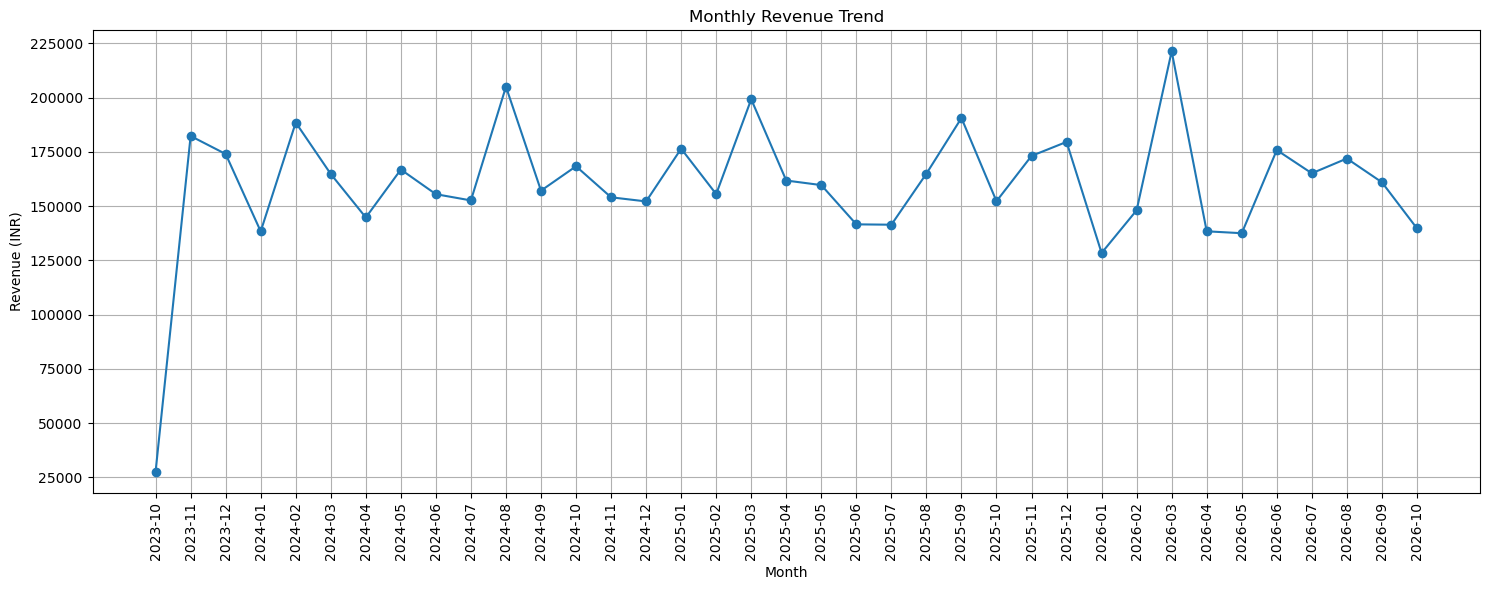

In [7]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_revenue["year_month"],
    monthly_revenue["total_revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
highest_month = monthly_revenue.loc[
    monthly_revenue["total_revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["total_revenue"].idxmin()
]

print("Highest Revenue Month:")
print(highest_month)

print("\nLowest Revenue Month:")
print(lowest_month)

Highest Revenue Month:
year_month            2026-03
total_revenue       221304.52
total_orders              122
unique_customers          117
Name: 29, dtype: object

Lowest Revenue Month:
year_month           2023-10
total_revenue       27712.56
total_orders              16
unique_customers          16
Name: 0, dtype: object


In [9]:
product_performance = (
    orders.groupby(["product_id", "product_name", "category"])
    .agg(
        total_revenue=("net_amount_inr", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        unique_customers=("user_id", "nunique")
    )
    .reset_index()
)

product_performance = product_performance.sort_values(
    by="total_revenue",
    ascending=False
)

display(product_performance)

,product_id,product_name,category,total_revenue,total_orders,units_sold,unique_customers
6,P3001,Mixer Grinder,Home & Kitchen,1051031.34,248,327,237
3,P2001,Running Shoes,Fashion,741694.72,262,350,253
1,P1002,Smart Watch,Electronics,657608.56,233,286,224
12,P5002,Cricket Bat,Sports,566102.47,243,322,233
0,P1001,Wireless Earbuds,Electronics,550980.73,248,327,243
2,P1003,Bluetooth Speaker,Electronics,466958.34,253,331,234
5,P2003,Backpack,Fashion,319372.92,200,263,193
8,P3003,Bedsheet Set,Home & Kitchen,291513.21,247,312,237
11,P5001,Yoga Mat,Sports,251019.27,227,295,217
14,P6002,Python Programming,Books,243702.29,253,324,241


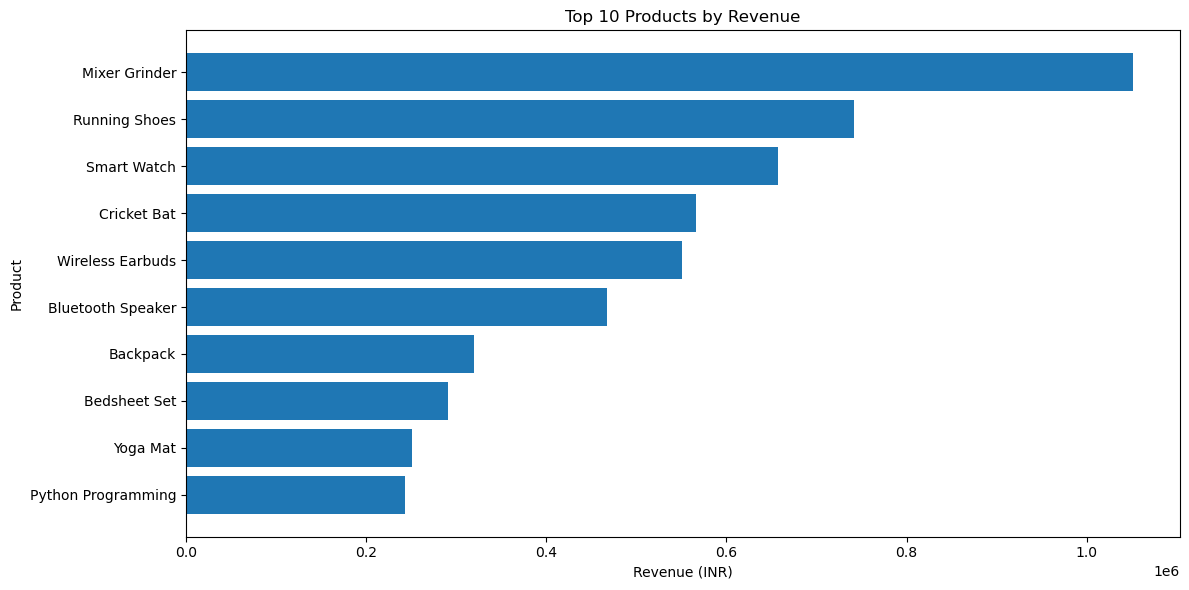

In [10]:
top_products = product_performance.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["product_name"],
    top_products["total_revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (INR)")
plt.ylabel("Product")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

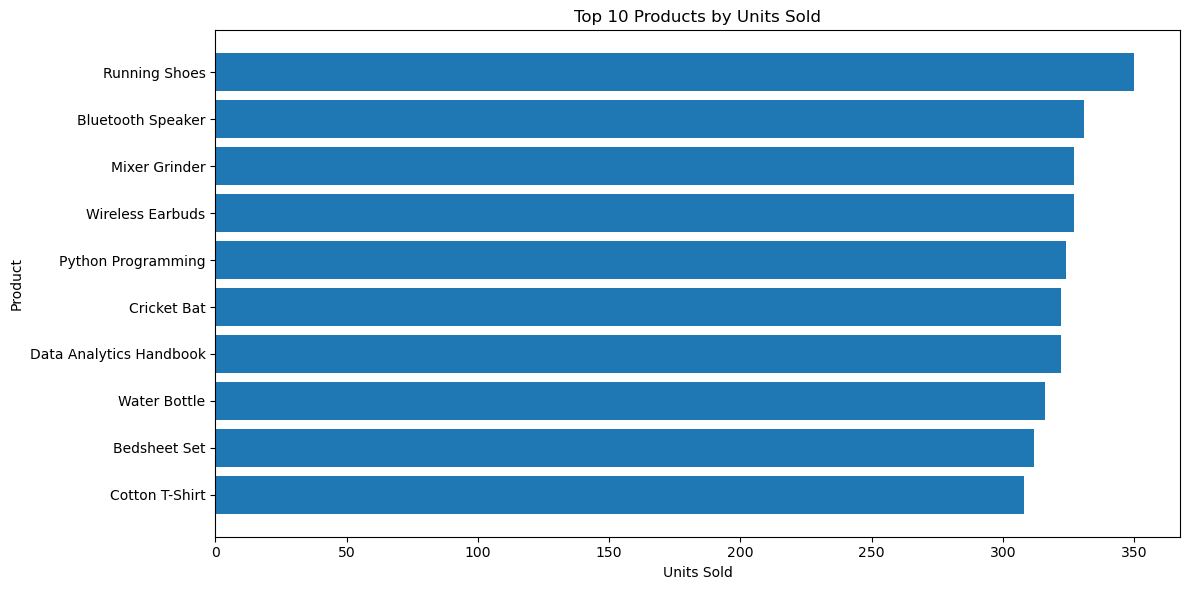

In [11]:
top_units = product_performance.sort_values(
    by="units_sold",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_units["product_name"],
    top_units["units_sold"]
)

plt.title("Top 10 Products by Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [14]:
best_revenue_product = product_performance.iloc[0]

best_selling_product = product_performance.loc[
    product_performance["units_sold"].idxmax()
]

print("Highest Revenue Product:")
print(best_revenue_product)

print("\nHighest Units Sold Product:")
print(best_selling_product)

Highest Revenue Product:
product_id                   P3001
product_name         Mixer Grinder
category            Home & Kitchen
total_revenue           1051031.34
total_orders                   248
units_sold                     327
unique_customers               237
Name: 6, dtype: object

Highest Units Sold Product:
product_id                  P2001
product_name        Running Shoes
category                  Fashion
total_revenue           741694.72
total_orders                  262
units_sold                    350
unique_customers              253
Name: 3, dtype: object


Category performance analysis

Revenue by category

In [15]:
category_performance = (
    orders.groupby("category")
    .agg(
        total_revenue=("net_amount_inr", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        unique_customers=("user_id", "nunique")
    )
    .reset_index()
)

category_performance = category_performance.sort_values(
    "total_revenue",
    ascending=False
)

display(category_performance)

,category,total_revenue,total_orders,units_sold,unique_customers
2,Electronics,1675547.63,734,944,649
4,Home & Kitchen,1459871.17,743,955,652
3,Fashion,1232472.66,695,921,611
5,Sports,817121.74,470,617,428
1,Books,395238.37,509,646,470
0,Beauty,335582.43,449,578,421


Category revenue contribution

In [16]:
category_performance["revenue_percentage"] = (
    category_performance["total_revenue"]
    / category_performance["total_revenue"].sum()
) * 100

display(category_performance)

,category,total_revenue,total_orders,units_sold,unique_customers,revenue_percentage
2,Electronics,1675547.63,734,944,649,28.323101
4,Home & Kitchen,1459871.17,743,955,652,24.677352
3,Fashion,1232472.66,695,921,611,20.833456
5,Sports,817121.74,470,617,428,13.812452
1,Books,395238.37,509,646,470,6.681025
0,Beauty,335582.43,449,578,421,5.672614


Visualize category revenue

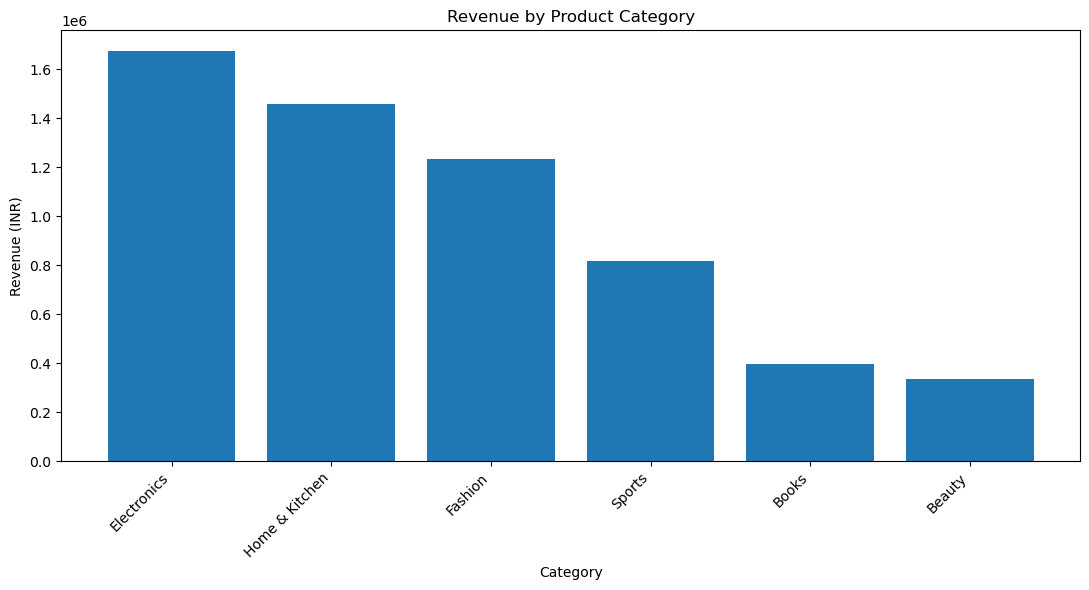

In [17]:
plt.figure(figsize=(11, 6))

plt.bar(
    category_performance["category"],
    category_performance["total_revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Revenue contribution chart

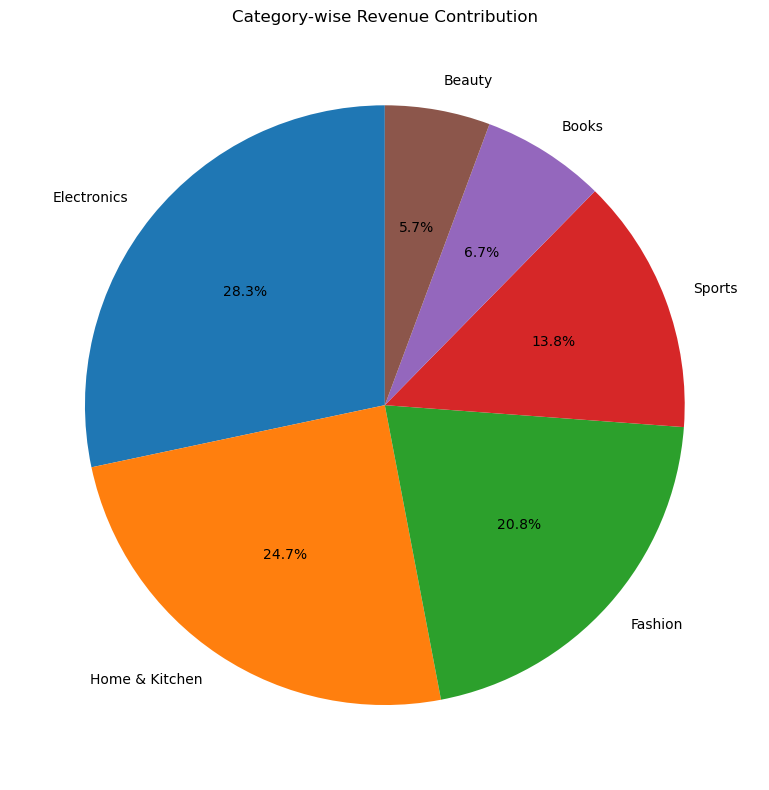

In [18]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_performance["total_revenue"],
    labels=category_performance["category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Category-wise Revenue Contribution")
plt.tight_layout()
plt.show()

Identify the strongest category

In [19]:
best_category = category_performance.iloc[0]

print("Highest Revenue Category:", best_category["category"])
print(f"Revenue: ₹{best_category['total_revenue']:,.2f}")
print(f"Revenue Contribution: {best_category['revenue_percentage']:.2f}%")

Highest Revenue Category: Electronics
Revenue: ₹1,675,547.63
Revenue Contribution: 28.32%


Business questions
1. How many customers are first-time versus repeat purchasers?
2. How many orders does each customer place?
3. Which customers generate the most revenue?
4. What percentage of customers make repeat purchases?

Orders per customer

In [21]:
customer_behavior = (
    orders.groupby("user_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("net_amount_inr", "sum"),
        average_order_value=("net_amount_inr", "mean"),
        total_units=("quantity", "sum")
    )
    .reset_index()
)

display(customer_behavior.head(10))

,user_id,total_orders,total_revenue,average_order_value,total_units
0,U00002,1,502.65,502.650000,1
1,U00003,2,2440.42,1220.210000,2
2,U00004,2,12631.97,6315.985000,6
3,U00005,1,447.15,447.150000,1
4,U00007,1,821.84,821.840000,1
5,U00010,3,2963.42,987.806667,3
6,U00012,1,1468.56,1468.560000,2
7,U00013,1,1868.62,1868.620000,1
8,U00014,3,7211.27,2403.756667,6
9,U00015,2,3295.66,1647.830000,3


First-time and repeat customers

In [22]:
customer_behavior["customer_type"] = np.where(
    customer_behavior["total_orders"] == 1,
    "One-time Customer",
    "Repeat Customer"
)

customer_summary = (
    customer_behavior["customer_type"]
    .value_counts()
    .reset_index()
)

customer_summary.columns = ["customer_type", "customer_count"]

customer_summary["percentage"] = (
    customer_summary["customer_count"]
    / customer_summary["customer_count"].sum()
) * 100

display(customer_summary)

,customer_type,customer_count,percentage
0,Repeat Customer,1050,53.70844
1,One-time Customer,905,46.29156


Visualize customer types

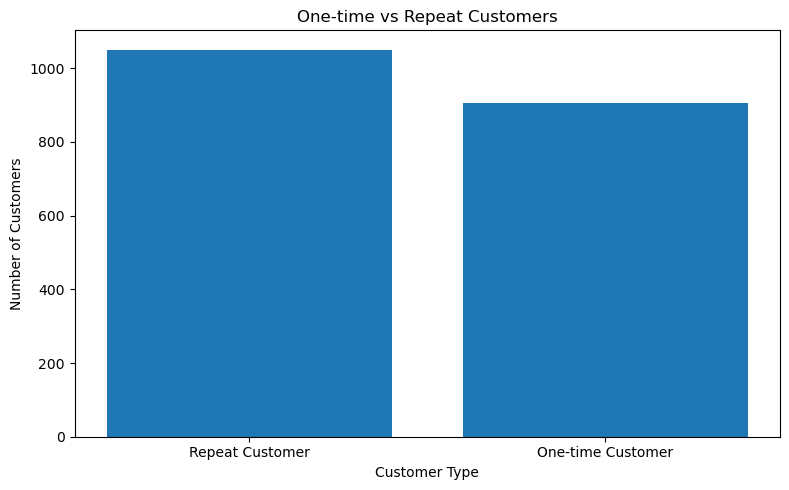

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(
    customer_summary["customer_type"],
    customer_summary["customer_count"]
)

plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Identify high-value customers

In [24]:
top_customers = customer_behavior.sort_values(
    "total_revenue",
    ascending=False
).head(10)

display(top_customers)

,user_id,total_orders,total_revenue,average_order_value,total_units,customer_type
1755,U02335,5,18247.61,3649.522000,8,Repeat Customer
610,U00815,3,16263.11,5421.036667,6,Repeat Customer
1202,U01595,4,15503.92,3875.980000,8,Repeat Customer
964,U01281,4,15107.84,3776.960000,8,Repeat Customer
670,U00892,4,14688.63,3672.157500,8,Repeat Customer
1572,U02098,4,13786.13,3446.532500,8,Repeat Customer
620,U00829,4,13698.56,3424.640000,6,Repeat Customer
316,U00432,3,13314.89,4438.296667,5,Repeat Customer
1692,U02248,3,13304.75,4434.916667,6,Repeat Customer
666,U00887,4,13041.55,3260.387500,6,Repeat Customer


Calculate repeat purchase rate

In [25]:
total_customers = customer_behavior["user_id"].nunique()

repeat_customers = (
    customer_behavior["total_orders"] > 1
).sum()

repeat_purchase_rate = (
    repeat_customers / total_customers
) * 100

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print(f"Repeat Purchase Rate: {repeat_purchase_rate:.2f}%")

Total Customers: 1955
Repeat Customers: 1050
Repeat Purchase Rate: 53.71%


City-wise revenue analysis

In [26]:
city_performance = (
    orders.groupby("city")
    .agg(
        total_revenue=("net_amount_inr", "sum"),
        total_orders=("order_id", "nunique"),
        unique_customers=("user_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
)

city_performance = city_performance.sort_values(
    "total_revenue",
    ascending=False
)

display(city_performance)

,city,total_revenue,total_orders,unique_customers,units_sold
6,Kolkata,690769.38,389,356,512
5,Jaipur,613429.35,365,338,457
3,Delhi,607612.12,362,342,493
7,Mumbai,601602.40,377,348,484
4,Hyderabad,587103.96,351,328,467
2,Chennai,582542.01,339,316,431
8,Pune,580946.17,363,336,455
0,Ahmedabad,546306.79,355,332,468
9,Vizag,521608.63,339,319,436
1,Bengaluru,515776.98,328,319,412


Calculate revenue contribution

In [27]:
city_performance["revenue_percentage"] = (
    city_performance["total_revenue"]
    / city_performance["total_revenue"].sum()
) * 100

display(city_performance)

,city,total_revenue,total_orders,unique_customers,units_sold,revenue_percentage
6,Kolkata,690769.38,389,356,512,11.812672
5,Jaipur,613429.35,365,338,457,10.490100
3,Delhi,607612.12,362,342,493,10.390621
7,Mumbai,601602.40,377,348,484,10.287850
4,Hyderabad,587103.96,351,328,467,10.039916
2,Chennai,582542.01,339,316,431,9.961903
8,Pune,580946.17,363,336,455,9.934613
0,Ahmedabad,546306.79,355,332,468,9.342254
9,Vizag,521608.63,339,319,436,8.919897
1,Bengaluru,515776.98,328,319,412,8.820172


Visualize city-wise revenue

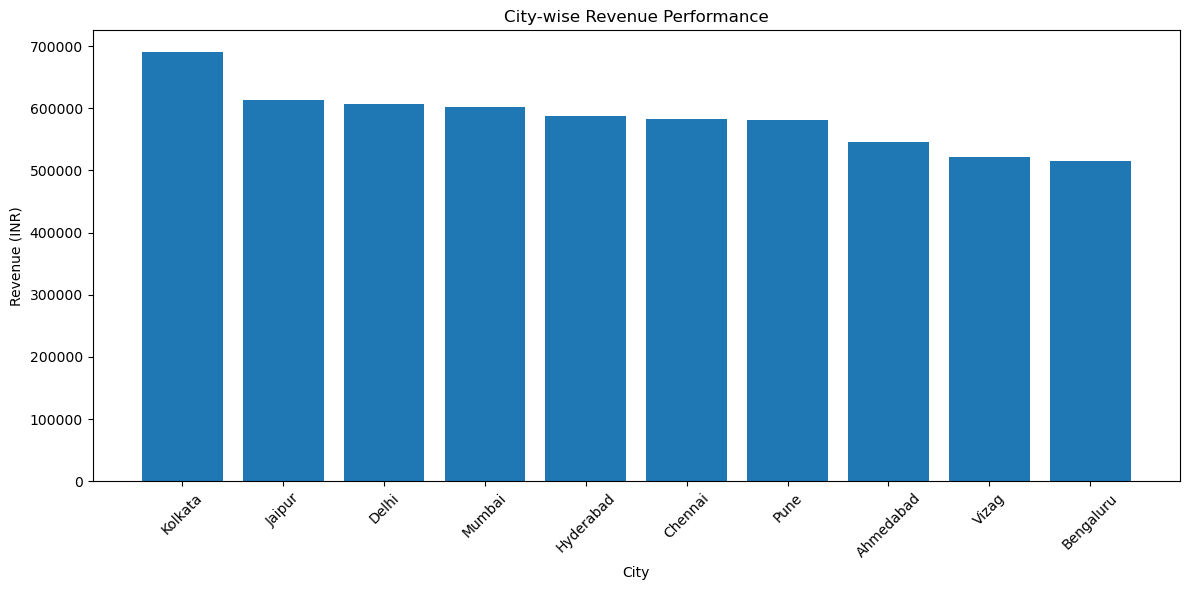

In [28]:
plt.figure(figsize=(12, 6))

plt.bar(
    city_performance["city"],
    city_performance["total_revenue"]
)

plt.title("City-wise Revenue Performance")
plt.xlabel("City")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Compare order volume by city

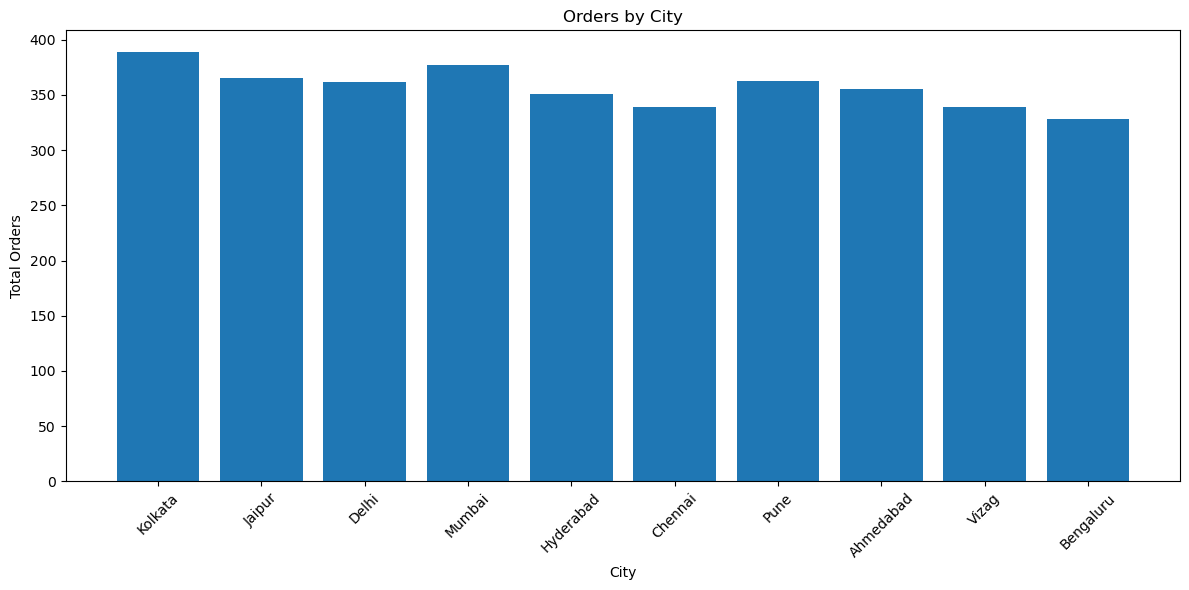

In [29]:
plt.figure(figsize=(12, 6))

plt.bar(
    city_performance["city"],
    city_performance["total_orders"]
)

plt.title("Orders by City")
plt.xlabel("City")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Identify the best-performing city

In [30]:
best_city = city_performance.iloc[0]

print("Highest Revenue City:", best_city["city"])
print(f"Total Revenue: ₹{best_city['total_revenue']:,.2f}")
print(f"Total Orders: {best_city['total_orders']}")
print(f"Unique Customers: {best_city['unique_customers']}")
print(f"Revenue Contribution: {best_city['revenue_percentage']:.2f}%")

Highest Revenue City: Kolkata
Total Revenue: ₹690,769.38
Total Orders: 389
Unique Customers: 356
Revenue Contribution: 11.81%


Count app events

In [31]:
event_summary = (
    events["event_name"]
    .value_counts()
    .reset_index()
)

event_summary.columns = ["event_name", "event_count"]

display(event_summary)

,event_name,event_count
0,view_item,3650
1,app_open,2131
2,add_to_cart,1869
3,search,1386
4,begin_checkout,1098
5,remove_from_cart,954
6,purchase,912


Count unique users at each funnel stage

In [33]:
funnel_events = [
    "view_item",
    "add_to_cart",
    "begin_checkout",
    "purchase"
]

funnel_data = []

for event in funnel_events:

    users = events.loc[
        events["event_name"] == event,
        "user_id"
    ].nunique()

    funnel_data.append({
        "stage": event,
        "unique_users": users
    })

funnel = pd.DataFrame(funnel_data)

display(funnel)

,stage,unique_users
0,view_item,1948
1,add_to_cart,1337
2,begin_checkout,918
3,purchase,761


Calculate stage conversion percentages

In [34]:
funnel["conversion_from_previous"] = (
    funnel["unique_users"]
    / funnel["unique_users"].shift(1)
) * 100

funnel["conversion_from_first_stage"] = (
    funnel["unique_users"]
    / funnel["unique_users"].iloc[0]
) * 100

display(funnel)

,stage,unique_users,conversion_from_previous,conversion_from_first_stage
0,view_item,1948,NaN,100.000000
1,add_to_cart,1337,68.634497,68.634497
2,begin_checkout,918,68.661182,47.125257
3,purchase,761,82.897603,39.065708


Visualize the funnel

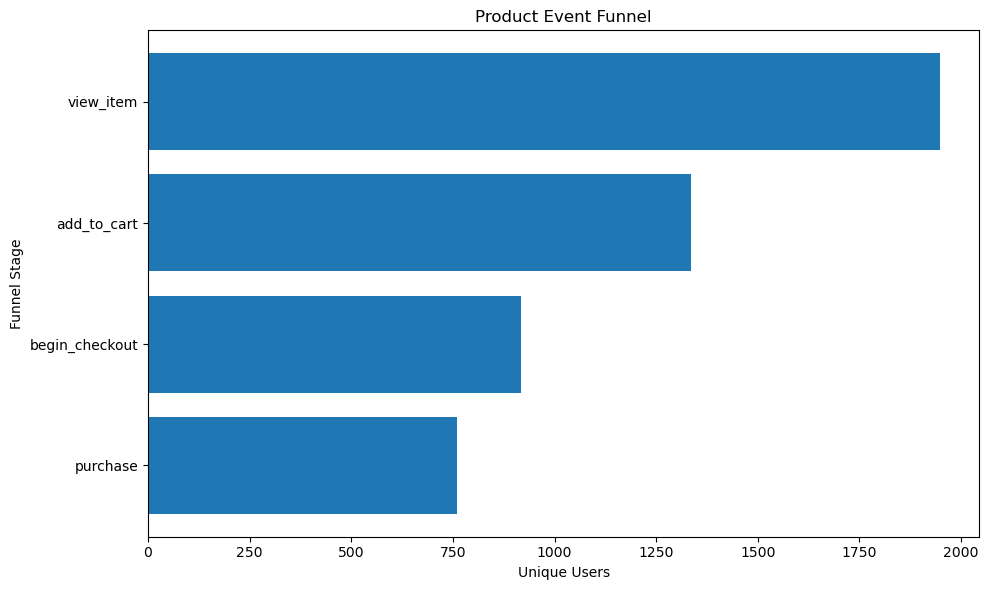

In [35]:
plt.figure(figsize=(10, 6))

plt.barh(
    funnel["stage"],
    funnel["unique_users"]
)

plt.title("Product Event Funnel")
plt.xlabel("Unique Users")
plt.ylabel("Funnel Stage")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Identify the largest stage-level drop

In [36]:
funnel["users_lost"] = (
    funnel["unique_users"].shift(1)
    - funnel["unique_users"]
)

display(funnel)

,stage,unique_users,conversion_from_previous,conversion_from_first_stage,users_lost
0,view_item,1948,NaN,100.000000,NaN
1,add_to_cart,1337,68.634497,68.634497,611.0
2,begin_checkout,918,68.661182,47.125257,419.0
3,purchase,761,82.897603,39.065708,157.0


Create session-level event timestamps

In [37]:
funnel_events = [
    "view_item",
    "add_to_cart",
    "begin_checkout",
    "purchase"
]

session_events = events[
    events["event_name"].isin(funnel_events)
].copy()

session_stage = (
    session_events.groupby(
        ["user_id", "session_id", "event_name"]
    )["event_timestamp"]
    .min()
    .unstack()
    .reset_index()
)

display(session_stage.head())

event_name,user_id,session_id,add_to_cart,begin_checkout,purchase,view_item
0,U00001,S003017,NaT,NaT,NaT,2025-10-07 02:26:54
1,U00002,S001084,2026-07-09 10:43:13,NaT,NaT,NaT
2,U00002,S001920,2025-06-04 12:31:45,NaT,NaT,NaT
3,U00004,S003670,NaT,NaT,NaT,2025-03-23 15:09:11
4,U00005,S002538,NaT,NaT,NaT,2025-11-18 07:25:30


Validate sequential funnel stages

In [38]:
session_stage["viewed"] = (
    session_stage["view_item"].notna()
)

session_stage["added_to_cart"] = (
    session_stage["viewed"]
    & session_stage["add_to_cart"].notna()
    & (session_stage["add_to_cart"] >= session_stage["view_item"])
)

session_stage["checkout_started"] = (
    session_stage["added_to_cart"]
    & session_stage["begin_checkout"].notna()
    & (session_stage["begin_checkout"] >= session_stage["add_to_cart"])
)

session_stage["purchased"] = (
    session_stage["checkout_started"]
    & session_stage["purchase"].notna()
    & (session_stage["purchase"] >= session_stage["begin_checkout"])
)

print("Sessions with product views:", session_stage["viewed"].sum())
print("Sessions with cart additions:", session_stage["added_to_cart"].sum())
print("Sessions with checkout:", session_stage["checkout_started"].sum())
print("Sessions with purchases:", session_stage["purchased"].sum())

Sessions with product views: 3649
Sessions with cart additions: 0
Sessions with checkout: 0
Sessions with purchases: 0


Calculate sequential conversion rates

In [39]:
sequential_funnel = pd.DataFrame({
    "stage": [
        "View Item",
        "Add to Cart",
        "Begin Checkout",
        "Purchase"
    ],
    "sessions": [
        session_stage["viewed"].sum(),
        session_stage["added_to_cart"].sum(),
        session_stage["checkout_started"].sum(),
        session_stage["purchased"].sum()
    ]
})

sequential_funnel["conversion_rate"] = (
    sequential_funnel["sessions"]
    / sequential_funnel["sessions"].shift(1)
) * 100

display(sequential_funnel)

,stage,sessions,conversion_rate
0,View Item,3649,NaN
1,Add to Cart,0,0.0
2,Begin Checkout,0,NaN
3,Purchase,0,NaN


Check whether event types share sessions

In [40]:
print("Unique sessions by event:")

print(
    events.groupby("event_name")["session_id"].nunique()
)

Unique sessions by event:
event_name
add_to_cart         1568
app_open            1737
begin_checkout      1006
purchase             836
remove_from_cart     872
search              1208
view_item           2630
Name: session_id, dtype: int64


Inspect sessions containing both view and cart events

In [41]:
session_event_counts = (
    events[
        events["event_name"].isin(
            ["view_item", "add_to_cart",
             "begin_checkout", "purchase"]
        )
    ]
    .groupby(["session_id", "event_name"])
    .size()
    .unstack(fill_value=0)
)

print("Sessions with both view and cart:")

print(
    (
        (session_event_counts["view_item"] > 0)
        & (session_event_counts["add_to_cart"] > 0)
    ).sum()
)

Sessions with both view and cart:
766


Inspect actual event records

Inspect sessions with both events

In [43]:
sample_sessions = session_event_counts[
    (session_event_counts["view_item"] > 0)
    & (session_event_counts["add_to_cart"] > 0)
].head(5).index

display(
    events[
        events["session_id"].isin(sample_sessions)
    ].sort_values(
        ["session_id", "event_timestamp"]
    )[
        [
            "user_id",
            "session_id",
            "event_name",
            "event_timestamp",
            "product_id"
        ]
    ]
)

,user_id,session_id,event_name,event_timestamp,product_id
5634,U02100,S000001,add_to_cart,2024-08-24 02:32:45,P4001
352,U01810,S000001,view_item,2025-07-19 13:19:03,P1003
5185,U01017,S000007,view_item,2023-12-18 18:32:19,P1001
7894,U01041,S000007,add_to_cart,2024-12-07 18:59:36,P2002
5663,U01696,S000019,add_to_cart,2023-11-29 00:06:44,P5001
2138,U01644,S000019,search,2023-12-23 13:45:25,NaN
3750,U00495,S000019,view_item,2024-02-03 20:53:24,P2003
10456,U02162,S000019,begin_checkout,2025-12-19 04:48:01,P1001
11648,U00418,S000019,view_item,2026-06-25 20:12:14,P4001
6275,U01892,S000034,begin_checkout,2023-11-04 04:15:56,P5002


Check chronological ordering

In [44]:
diagnostic = (
    events[
        events["event_name"].isin(
            ["view_item", "add_to_cart"]
        )
    ]
    .groupby(["session_id", "event_name"])
    ["event_timestamp"]
    .min()
    .unstack()
)

print("Sessions with both events:",
      diagnostic[["view_item", "add_to_cart"]].dropna().shape[0])

print("Cart after first view:",
      (
          diagnostic["add_to_cart"]
          >= diagnostic["view_item"]
      ).sum())

print("Cart before first view:",
      (
          diagnostic["add_to_cart"]
          < diagnostic["view_item"]
      ).sum())

Sessions with both events: 766
Cart after first view: 387
Cart before first view: 379


In [45]:
funnel_events = [
    "view_item",
    "add_to_cart",
    "begin_checkout",
    "purchase"
]

session_events = events[
    events["event_name"].isin(funnel_events)
].copy()

session_stage = (
    session_events.groupby(
        ["user_id", "session_id", "event_name"]
    )["event_timestamp"]
    .min()
    .unstack()
    .reset_index()
)

display(session_stage.head())

event_name,user_id,session_id,add_to_cart,begin_checkout,purchase,view_item
0,U00001,S003017,NaT,NaT,NaT,2025-10-07 02:26:54
1,U00002,S001084,2026-07-09 10:43:13,NaT,NaT,NaT
2,U00002,S001920,2025-06-04 12:31:45,NaT,NaT,NaT
3,U00004,S003670,NaT,NaT,NaT,2025-03-23 15:09:11
4,U00005,S002538,NaT,NaT,NaT,2025-11-18 07:25:30


In [46]:
session_stage["viewed"] = (
    session_stage["view_item"].notna()
)

session_stage["added_to_cart"] = (
    session_stage["viewed"]
    & session_stage["add_to_cart"].notna()
    & (
        session_stage["add_to_cart"]
        >= session_stage["view_item"]
    )
)

session_stage["checkout_started"] = (
    session_stage["added_to_cart"]
    & session_stage["begin_checkout"].notna()
    & (
        session_stage["begin_checkout"]
        >= session_stage["add_to_cart"]
    )
)

session_stage["purchased"] = (
    session_stage["checkout_started"]
    & session_stage["purchase"].notna()
    & (
        session_stage["purchase"]
        >= session_stage["begin_checkout"]
    )
)

print("View sessions:", session_stage["viewed"].sum())
print("Cart sessions:", session_stage["added_to_cart"].sum())
print("Checkout sessions:", session_stage["checkout_started"].sum())
print("Purchase sessions:", session_stage["purchased"].sum())

View sessions: 3649
Cart sessions: 0
Checkout sessions: 0
Purchase sessions: 0


In [51]:
sequential_funnel = pd.DataFrame({
    "stage": [
        "View Item",
        "Add to Cart",
        "Begin Checkout",
        "Purchase"
    ],
    "sessions": [
        session_stage["viewed"].sum(),
        session_stage["added_to_cart"].sum(),
        session_stage["checkout_started"].sum(),
        session_stage["purchased"].sum()
    ]
})

sequential_funnel["conversion_rate"] = (
    sequential_funnel["sessions"]
    / sequential_funnel["sessions"].shift(1)
) * 100

sequential_funnel["overall_conversion"] = (
    sequential_funnel["sessions"]
    / sequential_funnel["sessions"].iloc[0]
) * 100

display(sequential_funnel)

,stage,sessions,conversion_rate,overall_conversion
0,View Item,3649,NaN,100.0
1,Add to Cart,0,0.0,0.0
2,Begin Checkout,0,NaN,0.0
3,Purchase,0,NaN,0.0


Count unique user-session combinations

In [52]:
print("Unique user-session combinations:")

print(
    events[["user_id", "session_id"]]
    .drop_duplicates()
    .shape[0]
)

Unique user-session combinations:
11990


Check event overlap using both identifiers

In [53]:
session_overlap = (
    events[
        events["event_name"].isin(
            ["view_item", "add_to_cart",
             "begin_checkout", "purchase"]
        )
    ]
    .groupby(["user_id", "session_id", "event_name"])
    .size()
    .unstack(fill_value=0)
)

print("Sessions with view and cart:")
print(
    (
        (session_overlap["view_item"] > 0)
        & (session_overlap["add_to_cart"] > 0)
    ).sum()
)

print("\nSessions with cart and checkout:")
print(
    (
        (session_overlap["add_to_cart"] > 0)
        & (session_overlap["begin_checkout"] > 0)
    ).sum()session_activity = (
    events.groupby(["user_id", "session_id"])
    .size()
    .reset_index(name="event_count")
)

print(session_activity["event_count"].value_counts().sort_index())
)

print("\nSessions with checkout and purchase:")
print(
    (
        (session_overlap["begin_checkout"] > 0)
        & (session_overlap["purchase"] > 0)
    ).sum()
)session_activity = (
    events.groupby(["user_id", "session_id"])
    .size()
    .reset_index(name="event_count")
)

print(session_activity["event_count"].value_counts().sort_index())

Sessions with view and cart:
0

Sessions with cart and checkout:
0

Sessions with checkout and purchase:
3


Inspect the number of events per user-session

In [54]:
session_activity = (
    events.groupby(["user_id", "session_id"])
    .size()
    .reset_index(name="event_count")
)

print(session_activity["event_count"].value_counts().sort_index())

1    11980
2       10
Name: event_count, dtype: int64


In [55]:
event_engagement = (
    events.groupby("event_name")
    .agg(
        total_events=("event_id", "count"),
        unique_users=("user_id", "nunique"),
        unique_sessions=("session_id", "nunique")
    )
    .reset_index()
)

event_engagement["events_per_user"] = (
    event_engagement["total_events"]
    / event_engagement["unique_users"]
)

display(
    event_engagement.sort_values(
        "total_events",
        ascending=False
    )
)

,event_name,total_events,unique_users,unique_sessions,events_per_user
6,view_item,3650,1948,2630,1.873717
1,app_open,2131,1470,1737,1.449660
0,add_to_cart,1869,1337,1568,1.397906
5,search,1386,1072,1208,1.292910
2,begin_checkout,1098,918,1006,1.196078
4,remove_from_cart,954,774,872,1.232558
3,purchase,912,761,836,1.198423


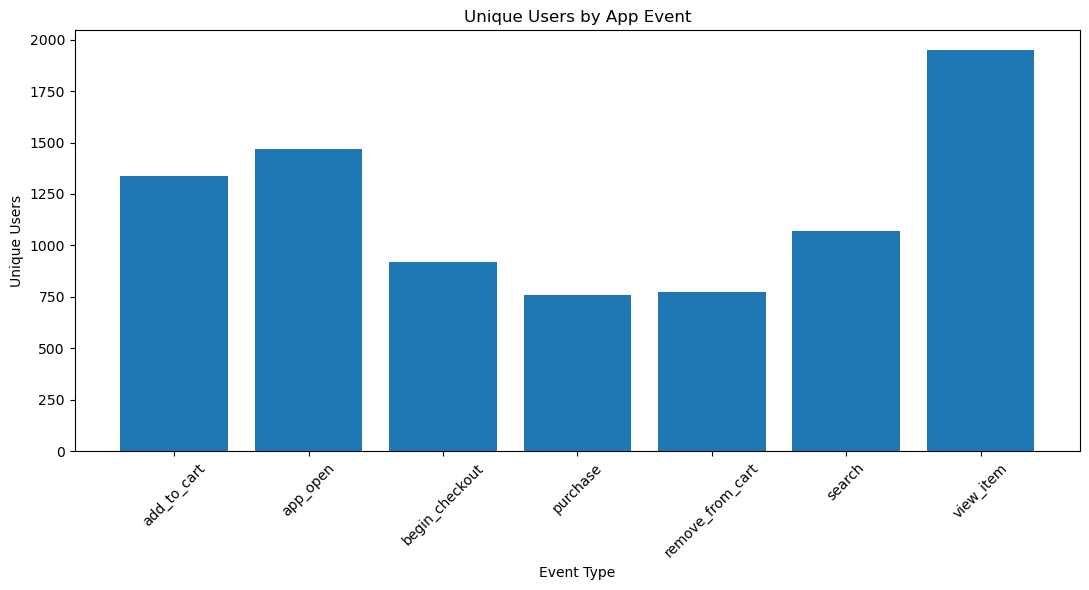

In [56]:
plt.figure(figsize=(11, 6))

plt.bar(
    event_engagement["event_name"],
    event_engagement["unique_users"]
)

plt.title("Unique Users by App Event")
plt.xlabel("Event Type")
plt.ylabel("Unique Users")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [57]:
events["year_month"] = (
    events["event_timestamp"].dt.to_period("M")
)

monthly_activity = (
    events.groupby("year_month")
    .agg(
        total_events=("event_id", "count"),
        active_users=("user_id", "nunique"),
        active_sessions=("session_id", "nunique")
    )
    .reset_index()
)

monthly_activity["year_month"] = (
    monthly_activity["year_month"].astype(str)
)

display(monthly_activity.head(10))

,year_month,total_events,active_users,active_sessions
0,2023-10,36,36,36
1,2023-11,355,326,341
2,2023-12,336,313,325
3,2024-01,331,305,322
4,2024-02,313,291,305
5,2024-03,350,326,339
6,2024-04,326,311,316
7,2024-05,339,312,324
8,2024-06,330,308,321
9,2024-07,346,324,332


Monthly active users trend

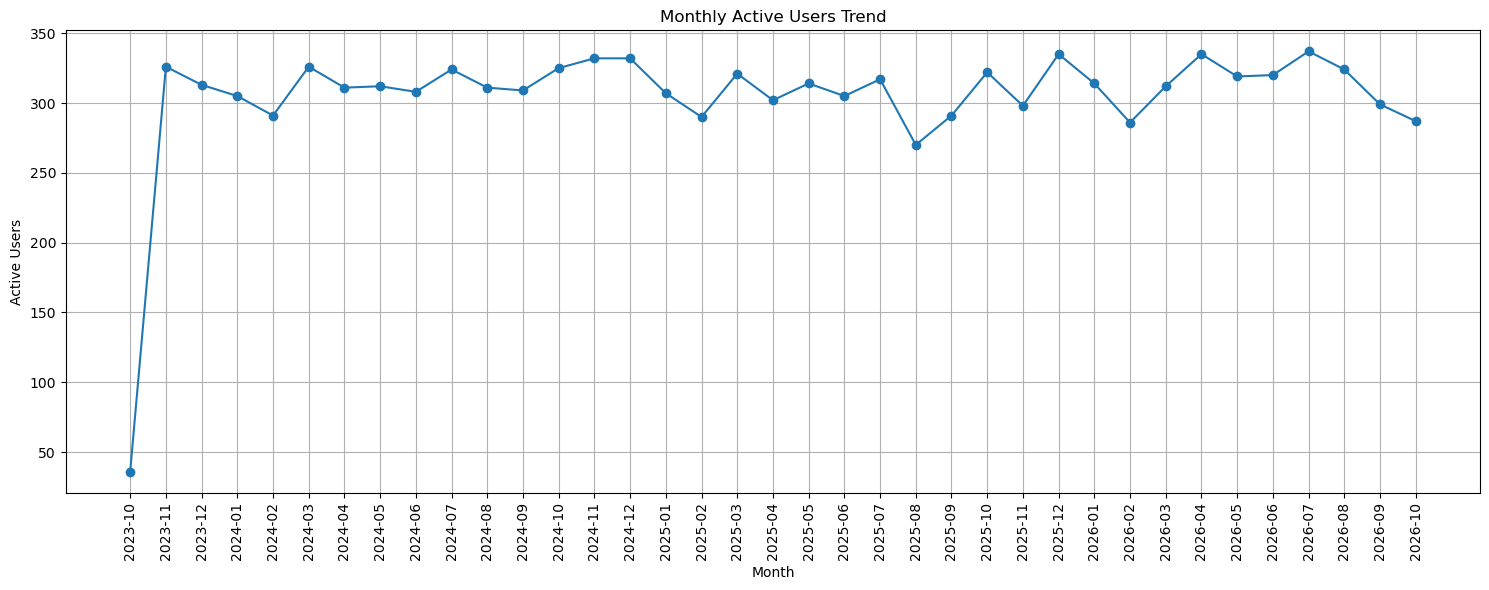

In [58]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_activity["year_month"],
    monthly_activity["active_users"],
    marker="o"
)

plt.title("Monthly Active Users Trend")
plt.xlabel("Month")
plt.ylabel("Active Users")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

Monthly event activity

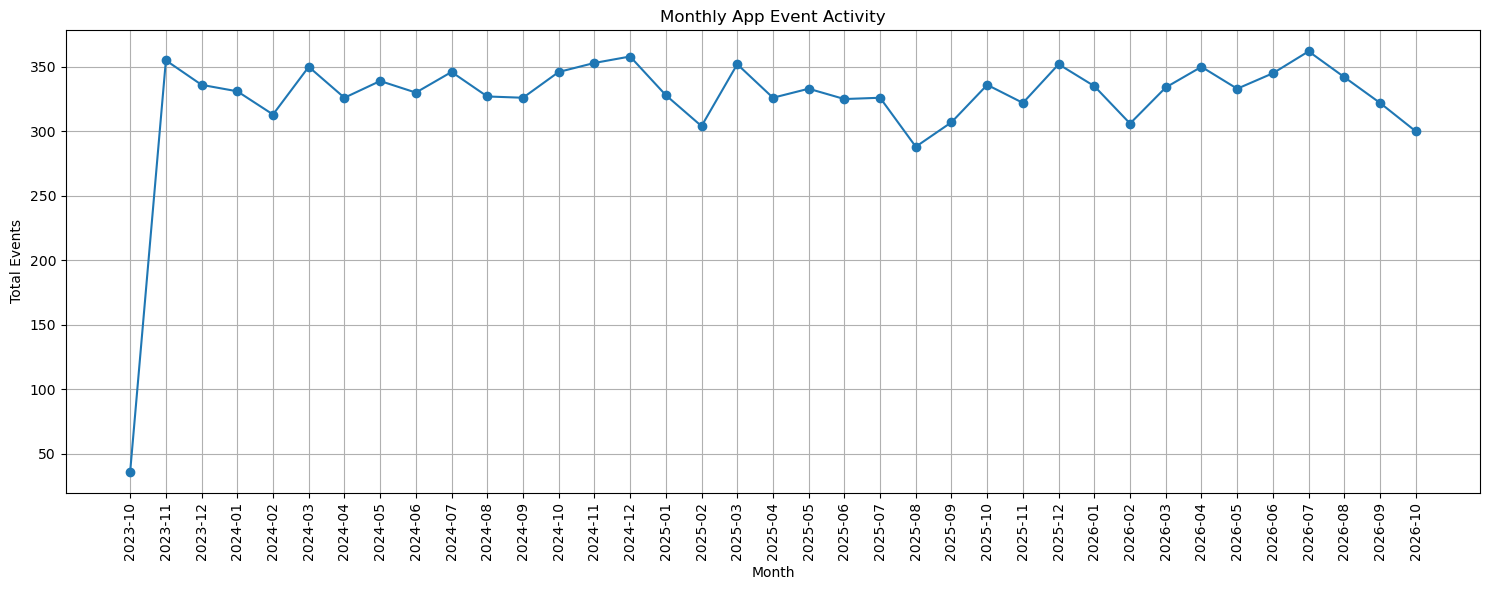

In [59]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_activity["year_month"],
    monthly_activity["total_events"],
    marker="o"
)

plt.title("Monthly App Event Activity")
plt.xlabel("Month")
plt.ylabel("Total Events")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

Find highest and lowest activity months

In [60]:
highest_activity = monthly_activity.loc[
    monthly_activity["active_users"].idxmax()
]

lowest_activity = monthly_activity.loc[
    monthly_activity["active_users"].idxmin()
]

print("Highest Active User Month:")
print(highest_activity)

print("\nLowest Active User Month:")
print(lowest_activity)

Highest Active User Month:
year_month         2026-07
total_events           362
active_users           337
active_sessions        348
Name: 33, dtype: object

Lowest Active User Month:
year_month         2023-10
total_events            36
active_users            36
active_sessions         36
Name: 0, dtype: object


Identify each customer's first purchase month

In [61]:
orders["order_month"] = (
    orders["order_date"].dt.to_period("M")
)

customer_cohort = (
    orders.groupby("user_id")["order_month"]
    .min()
    .reset_index()
)

customer_cohort.columns = [
    "user_id",
    "cohort_month"
]

display(customer_cohort.head(10))

,user_id,cohort_month
0,U00002,2025-07
1,U00003,2024-07
2,U00004,2024-06
3,U00005,2024-05
4,U00007,2026-04
5,U00010,2023-11
6,U00012,2026-06
7,U00013,2024-08
8,U00014,2023-11
9,U00015,2025-07


Combine cohort and order information

In [62]:
cohort_data = orders.merge(
    customer_cohort,
    on="user_id",
    how="left"
)

cohort_data["cohort_index"] = (
    (cohort_data["order_month"].dt.year
     - cohort_data["cohort_month"].dt.year) * 12
    +
    (cohort_data["order_month"].dt.month
     - cohort_data["cohort_month"].dt.month)
)

display(cohort_data.head(10))

,order_id,order_date,user_id,product_id,product_name,category,city,quantity,unit_price_inr,discount_pct,...,net_amount_inr,payment_method,order_status,acquisition_channel,device,discount_pct_clean,year_month,order_month,cohort_month,cohort_index
0,ORD000001,2024-03-19,U02305,P2002,Cotton T-Shirt,Fashion,Kolkata,2,603.90,5.0,...,1147.40,Debit Card,Delivered,Direct,Android,5.0,2024-03,2024-03,2024-03,0
1,ORD000002,2026-10-27,U00202,P3003,Bedsheet Set,Home & Kitchen,Pune,1,899.94,0.0,...,899.94,Net Banking,Delivered,Paid Search,Android,0.0,2026-10,2026-10,2023-11,35
2,ORD000003,2024-02-26,U02316,P3001,Mixer Grinder,Home & Kitchen,Hyderabad,1,3100.13,20.0,...,2480.10,COD,Delivered,Email,Android,20.0,2024-02,2024-02,2024-02,0
3,ORD000004,2026-06-09,U01746,P3003,Bedsheet Set,Home & Kitchen,Chennai,4,942.26,0.0,...,3769.05,COD,Cancelled,Organic Search,Android,0.0,2026-06,2026-06,2024-06,24
4,ORD000005,2024-11-10,U01447,P5002,Cricket Bat,Sports,Chennai,2,1806.36,0.0,...,3612.73,Wallet,Delivered,Social Media,iOS,0.0,2024-11,2024-11,2024-08,3
5,ORD000006,2026-09-01,U00385,P2001,Running Shoes,Fashion,Ahmedabad,1,2613.67,0.0,...,2613.67,Debit Card,Delivered,Paid Search,iOS,0.0,2026-09,2026-09,2026-09,0
6,ORD000007,2025-08-07,U02000,P1001,Wireless Earbuds,Electronics,Jaipur,1,1584.74,0.0,...,1584.74,Wallet,Delivered,Social Media,iOS,0.0,2025-08,2025-08,2025-08,0
7,ORD000008,2026-02-10,U01623,P3002,Water Bottle,Home & Kitchen,Jaipur,1,398.95,0.0,...,398.95,Net Banking,Delivered,Social Media,iOS,0.0,2026-02,2026-02,2025-12,2
8,ORD000009,2025-02-14,U02034,P5001,Yoga Mat,Sports,Vizag,3,876.02,15.0,...,2233.85,Debit Card,Cancelled,Paid Search,Web,15.0,2025-02,2025-02,2024-05,9
9,ORD000010,2026-07-20,U01720,P6001,Data Analytics Handbook,Books,Mumbai,1,482.43,20.0,...,385.94,Wallet,Delivered,Paid Search,Web,20.0,2026-07,2026-07,2024-10,21


In [63]:
cohort_table = (
    cohort_data.groupby(
        ["cohort_month", "cohort_index"]
    )["user_id"]
    .nunique()
    .unstack()
)

display(cohort_table)

cohort_index,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-10,16.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,1.0,NaN,...,1.0,NaN,1.0,NaN,NaN,1.0,2.0,1.0,NaN,1.0
2023-11,106.0,5.0,2.0,4.0,3.0,1.0,2.0,2.0,4.0,2.0,...,5.0,2.0,3.0,4.0,5.0,3.0,3.0,NaN,2.0,NaN
2023-12,98.0,7.0,7.0,4.0,2.0,2.0,3.0,3.0,2.0,4.0,...,7.0,NaN,4.0,3.0,1.0,4.0,3.0,5.0,NaN,NaN
2024-01,78.0,2.0,4.0,4.0,2.0,4.0,4.0,1.0,4.0,2.0,...,6.0,6.0,4.0,4.0,1.0,2.0,1.0,NaN,NaN,NaN
2024-02,104.0,4.0,5.0,7.0,3.0,3.0,7.0,2.0,4.0,4.0,...,2.0,6.0,2.0,5.0,5.0,4.0,NaN,NaN,NaN,NaN
2024-03,85.0,3.0,3.0,6.0,5.0,4.0,1.0,2.0,3.0,1.0,...,2.0,NaN,4.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN
2024-04,82.0,2.0,3.0,3.0,2.0,4.0,NaN,1.0,3.0,4.0,...,2.0,1.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN
2024-05,97.0,2.0,3.0,3.0,4.0,NaN,3.0,1.0,1.0,5.0,...,4.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-06,78.0,5.0,3.0,1.0,3.0,3.0,2.0,1.0,3.0,1.0,...,NaN,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


retention percentages

In [64]:
cohort_sizes = cohort_table.iloc[:, 0]

retention_table = cohort_table.divide(
    cohort_sizes,
    axis=0
) * 100

display(retention_table.round(2))

cohort_index,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-10,100.0,NaN,6.25,12.50,NaN,12.50,NaN,NaN,6.25,NaN,...,6.25,NaN,6.25,NaN,NaN,6.25,12.50,6.25,NaN,6.25
2023-11,100.0,4.72,1.89,3.77,2.83,0.94,1.89,1.89,3.77,1.89,...,4.72,1.89,2.83,3.77,4.72,2.83,2.83,NaN,1.89,NaN
2023-12,100.0,7.14,7.14,4.08,2.04,2.04,3.06,3.06,2.04,4.08,...,7.14,NaN,4.08,3.06,1.02,4.08,3.06,5.10,NaN,NaN
2024-01,100.0,2.56,5.13,5.13,2.56,5.13,5.13,1.28,5.13,2.56,...,7.69,7.69,5.13,5.13,1.28,2.56,1.28,NaN,NaN,NaN
2024-02,100.0,3.85,4.81,6.73,2.88,2.88,6.73,1.92,3.85,3.85,...,1.92,5.77,1.92,4.81,4.81,3.85,NaN,NaN,NaN,NaN
2024-03,100.0,3.53,3.53,7.06,5.88,4.71,1.18,2.35,3.53,1.18,...,2.35,NaN,4.71,4.71,4.71,NaN,NaN,NaN,NaN,NaN
2024-04,100.0,2.44,3.66,3.66,2.44,4.88,NaN,1.22,3.66,4.88,...,2.44,1.22,4.88,4.88,NaN,NaN,NaN,NaN,NaN,NaN
2024-05,100.0,2.06,3.09,3.09,4.12,NaN,3.09,1.03,1.03,5.15,...,4.12,4.12,4.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-06,100.0,6.41,3.85,1.28,3.85,3.85,2.56,1.28,3.85,1.28,...,NaN,6.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


retention heatmap

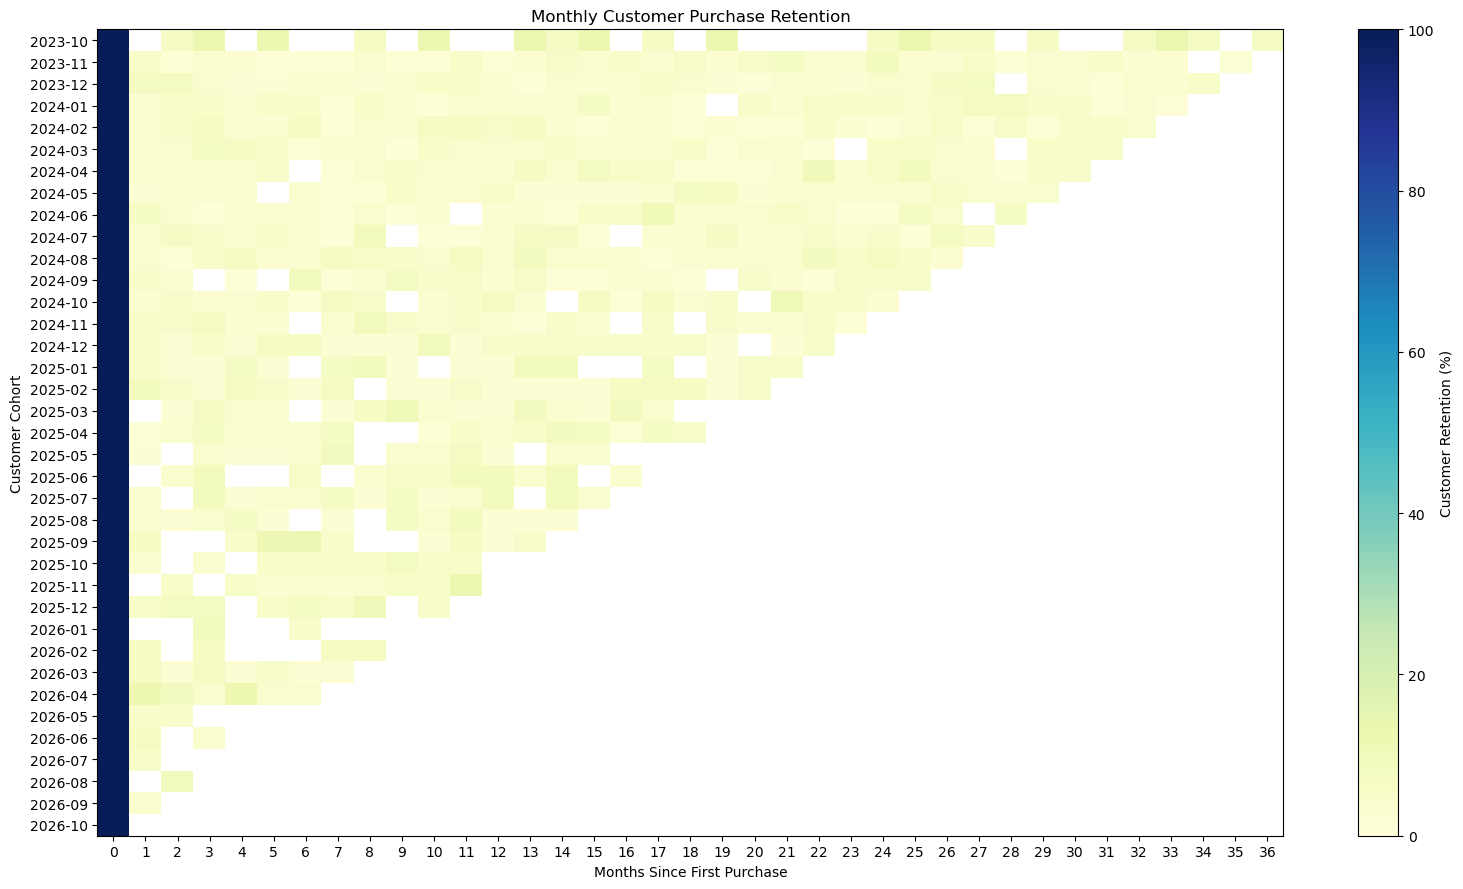

In [65]:
plt.figure(figsize=(16, 9))

plt.imshow(
    retention_table,
    aspect="auto",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Customer Retention (%)")

plt.title("Monthly Customer Purchase Retention")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")

plt.xticks(
    range(len(retention_table.columns)),
    retention_table.columns
)

plt.yticks(
    range(len(retention_table.index)),
    retention_table.index.astype(str)
)

plt.tight_layout()
plt.show()

Payment method performance

In [66]:
payment_analysis = (
    orders.groupby("payment_method")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("net_amount_inr", "sum"),
        unique_customers=("user_id", "nunique")
    )
    .reset_index()
)

payment_analysis["revenue_percentage"] = (
    payment_analysis["total_revenue"]
    / payment_analysis["total_revenue"].sum()
) * 100

payment_analysis = payment_analysis.sort_values(
    "total_revenue",
    ascending=False
)

display(payment_analysis)

,payment_method,total_orders,total_revenue,unique_customers,revenue_percentage
1,Credit Card,634,1038980.73,576,17.562709
2,Debit Card,639,1032030.40,568,17.445222
3,Net Banking,611,1016881.14,542,17.189143
4,UPI,578,972686.64,518,16.442088
5,Wallet,570,950362.09,516,16.064719
0,COD,568,904893.00,505,15.296119


Visualize payment method usage

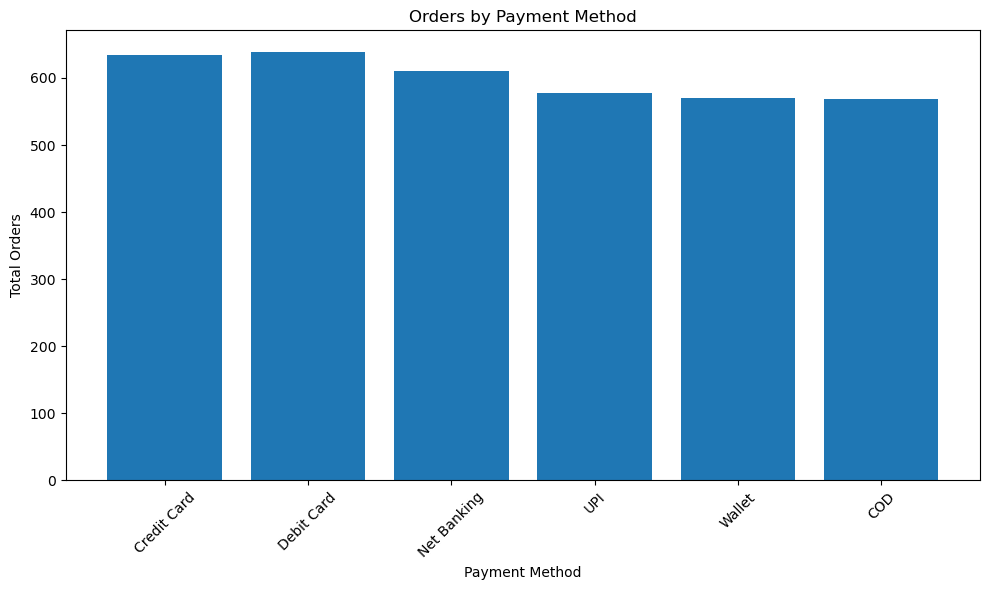

In [67]:
plt.figure(figsize=(10, 6))

plt.bar(
    payment_analysis["payment_method"],
    payment_analysis["total_orders"]
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Compare revenue by payment method

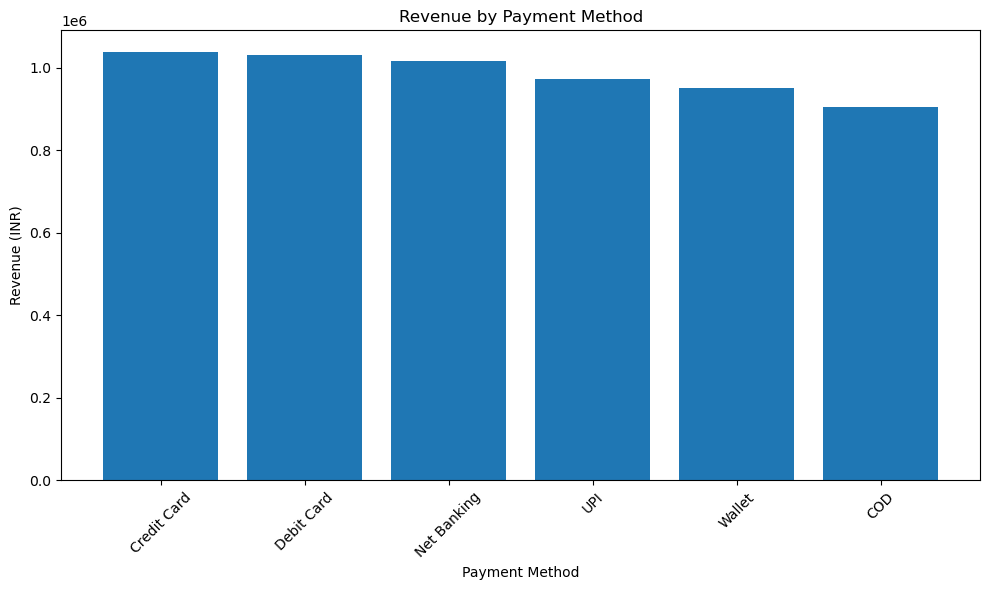

In [68]:
plt.figure(figsize=(10, 6))

plt.bar(
    payment_analysis["payment_method"],
    payment_analysis["total_revenue"]
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Identify the leading payment method

In [69]:
best_payment = payment_analysis.iloc[0]

print("Top Payment Method:", best_payment["payment_method"])
print(f"Orders: {best_payment['total_orders']:,}")
print(f"Revenue: ₹{best_payment['total_revenue']:,.2f}")
print(
    f"Revenue Contribution: "
    f"{best_payment['revenue_percentage']:.2f}%"
)

Top Payment Method: Credit Card
Orders: 634
Revenue: ₹1,038,980.73
Revenue Contribution: 17.56%


Order status analysis

In [70]:
order_status_analysis = (
    orders.groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("net_amount_inr", "sum")
    )
    .reset_index()
)

order_status_analysis["order_percentage"] = (
    order_status_analysis["total_orders"]
    / order_status_analysis["total_orders"].sum()
) * 100

display(order_status_analysis)

,order_status,total_orders,total_revenue,order_percentage
0,Cancelled,287,439382.77,7.972222
1,DELIVERED,16,27498.84,0.444444
2,Delivered,2534,4253165.04,70.388889
3,Processing,183,312786.30,5.083333
4,RETURNED,2,3766.48,0.055556
5,Returned,226,373717.64,6.277778
6,Shipped,352,505516.93,9.777778


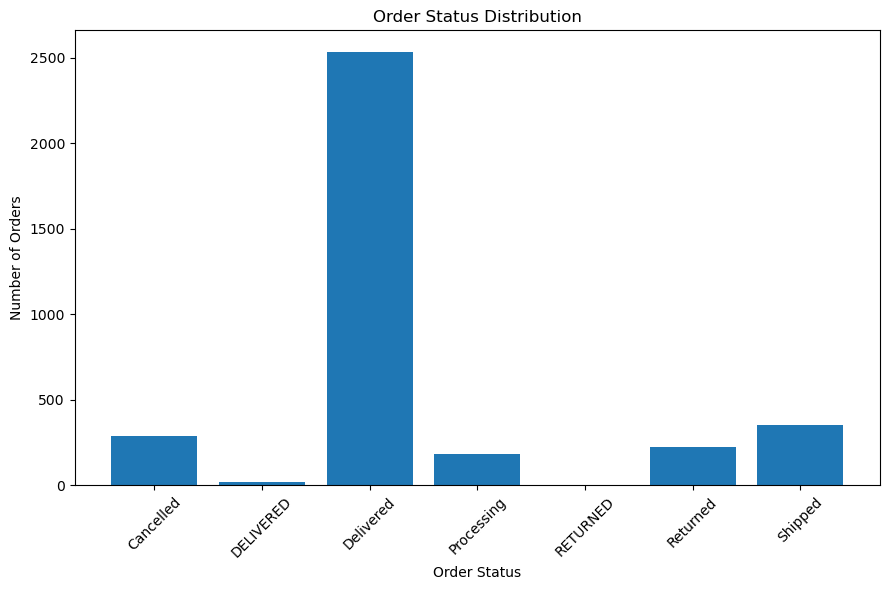

In [71]:
plt.figure(figsize=(9, 6))

plt.bar(
    order_status_analysis["order_status"],
    order_status_analysis["total_orders"]
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Revenue and order trends by year

In [72]:
orders["year"] = orders["order_date"].dt.year

yearly_performance = (
    orders.groupby("year")
    .agg(
        total_revenue=("net_amount_inr", "sum"),
        total_orders=("order_id", "nunique"),
        unique_customers=("user_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
)

display(yearly_performance)

,year,total_revenue,total_orders,unique_customers,units_sold
0,2023,384026.74,227,220,290
1,2024,1948120.36,1217,980,1566
2,2025,1996304.93,1181,954,1529
3,2026,1587381.97,975,818,1276


year-over-year revenue growth

In [73]:
yearly_performance["revenue_growth_pct"] = (
    yearly_performance["total_revenue"].pct_change()
    * 100
)

yearly_performance["order_growth_pct"] = (
    yearly_performance["total_orders"].pct_change()
    * 100
)

display(yearly_performance.round(2))

,year,total_revenue,total_orders,unique_customers,units_sold,revenue_growth_pct,order_growth_pct
0,2023,384026.74,227,220,290,NaN,NaN
1,2024,1948120.36,1217,980,1566,407.29,436.12
2,2025,1996304.93,1181,954,1529,2.47,-2.96
3,2026,1587381.97,975,818,1276,-20.48,-17.44


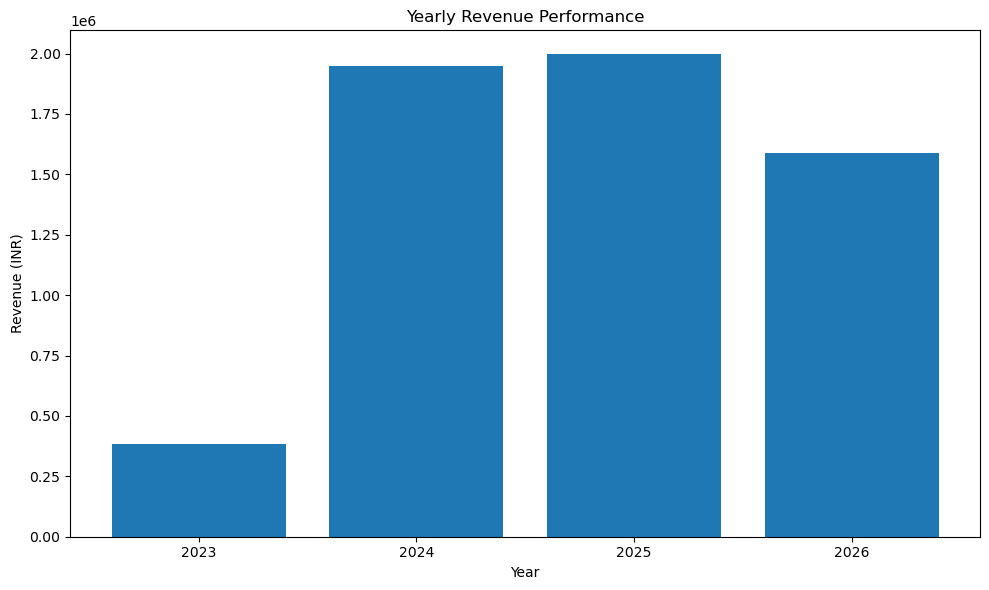

In [74]:
plt.figure(figsize=(10, 6))

plt.bar(
    yearly_performance["year"].astype(str),
    yearly_performance["total_revenue"]
)

plt.title("Yearly Revenue Performance")
plt.xlabel("Year")
plt.ylabel("Revenue (INR)")

plt.tight_layout()
plt.show()

KPI summary

In [75]:
eda_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Unique Customers",
        "Average Order Value",
        "Unique Products",
        "Unique Cities",
        "Total App Events",
        "Unique App Users"
    ],
    "Value": [
        orders["net_amount_inr"].sum(),
        orders["order_id"].nunique(),
        orders["user_id"].nunique(),
        orders["net_amount_inr"].sum()
            / orders["order_id"].nunique(),
        orders["product_id"].nunique(),
        orders["city"].nunique(),
        events["event_id"].nunique(),
        events["user_id"].nunique()
    ]
})

display(eda_summary)

,KPI,Value
0,Total Revenue,5.915834e+06
1,Total Orders,3.600000e+03
2,Unique Customers,1.955000e+03
3,Average Order Value,1.643287e+03
4,Unique Products,1.500000e+01
5,Unique Cities,1.000000e+01
6,Total App Events,1.200000e+04
7,Unique App Users,2.582000e+03


In [76]:
import os

report_path = "E:/Product_Analyst/reports"

os.makedirs(report_path, exist_ok=True)

monthly_revenue.to_csv(
    os.path.join(report_path, "monthly_revenue.csv"),
    index=False
)

product_performance.to_csv(
    os.path.join(report_path, "product_performance.csv"),
    index=False
)

category_performance.to_csv(
    os.path.join(report_path, "category_performance.csv"),
    index=False
)

customer_behavior.to_csv(
    os.path.join(report_path, "customer_behavior.csv"),
    index=False
)

city_performance.to_csv(
    os.path.join(report_path, "city_performance.csv"),
    index=False
)

payment_analysis.to_csv(
    os.path.join(report_path, "payment_analysis.csv"),
    index=False
)

yearly_performance.to_csv(
    os.path.join(report_path, "yearly_performance.csv"),
    index=False
)

eda_summary.to_csv(
    os.path.join(report_path, "eda_kpi_summary.csv"),
    index=False
)

print("EDA reports exported successfully!")

EDA reports exported successfully!
